CISC7204 Assignment 02 — MC63582 FAN ZIQIAN

# Pie Charts, Box Plots, Scatter Plots, and Bubble Plots

Immigration to Canada, 1980–2013.

## Prepare the Canada immigration dataset

In [11]:
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.style.use('ggplot')

df_can = pd.read_excel(
    'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/Canada.xlsx',
    sheet_name='Canada by Citizenship',
    skiprows=range(20),
    skipfooter=2,
)
df_can.drop(['AREA', 'REG', 'DEV', 'Type', 'Coverage'], axis=1, inplace=True)
df_can.rename(columns={'OdName': 'Country', 'AreaName': 'Continent', 'RegName': 'Region'}, inplace=True)
df_can['Total'] = df_can.select_dtypes(include='number').sum(axis=1)
df_can.set_index('Country', inplace=True)
df_can.columns = list(map(str, df_can.columns))
years = list(map(str, range(1980, 2014)))
print('data dimensions:', df_can.shape)
df_can.head(3)


data dimensions: (195, 38)


,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Country,,,,,,,,,,,,,,,,,,,,,
Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,496,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,1,...,1223,856,702,560,716,561,539,620,603,15699
Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,69,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439


## Pie chart

What share of total immigration, 1980–2013, came from each continent?

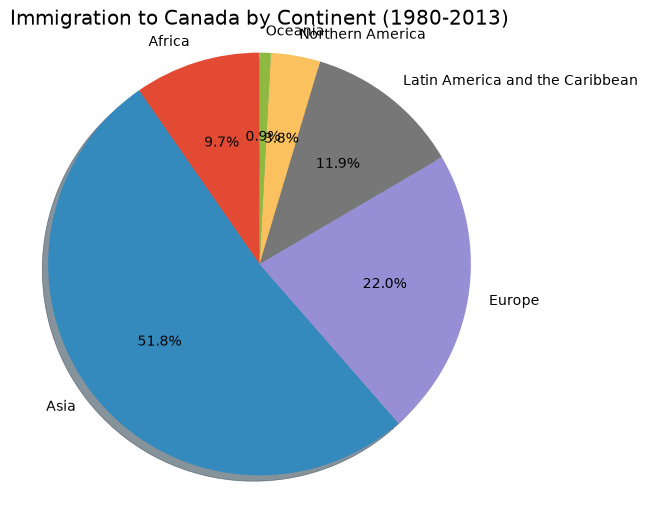

In [12]:
df_continents = df_can.groupby('Continent')['Total'].sum()
df_continents.plot(kind='pie', figsize=(6, 6), autopct='%1.1f%%', startangle=90, shadow=True)
plt.title('Immigration to Canada by Continent (1980-2013)')
plt.axis('equal')
plt.show()


**Question.** Improve the pie chart: percentages a little outside the wedges, a legend instead of labels on the wedges, and listed colors.

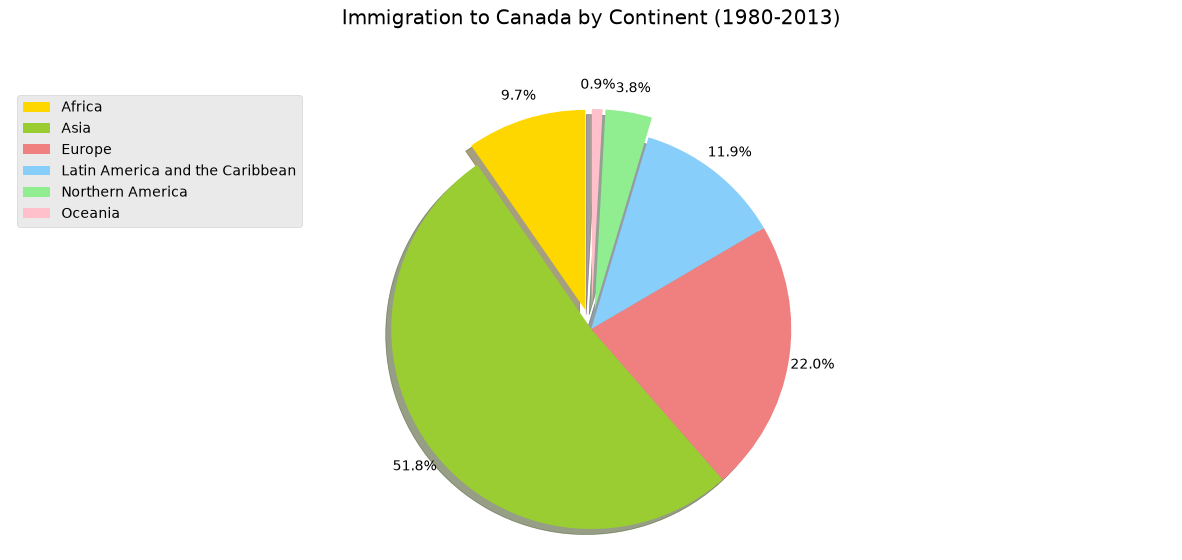

In [13]:
colors_list = ['gold', 'yellowgreen', 'lightcoral', 'lightskyblue', 'lightgreen', 'pink']
explode_list = [0.1, 0, 0, 0, 0.1, 0.1]
df_continents.plot(
    kind='pie',
    figsize=(15, 6),
    autopct='%1.1f%%',
    startangle=90,
    shadow=True,
    labels=None,
    pctdistance=1.12,
    colors=colors_list,
    explode=explode_list,
)
plt.title('Immigration to Canada by Continent (1980-2013)', y=1.12)
plt.axis('equal')
plt.legend(labels=df_continents.index, loc='upper left')
plt.show()


## Box plot

Immigration from Japan, 1980–2013.

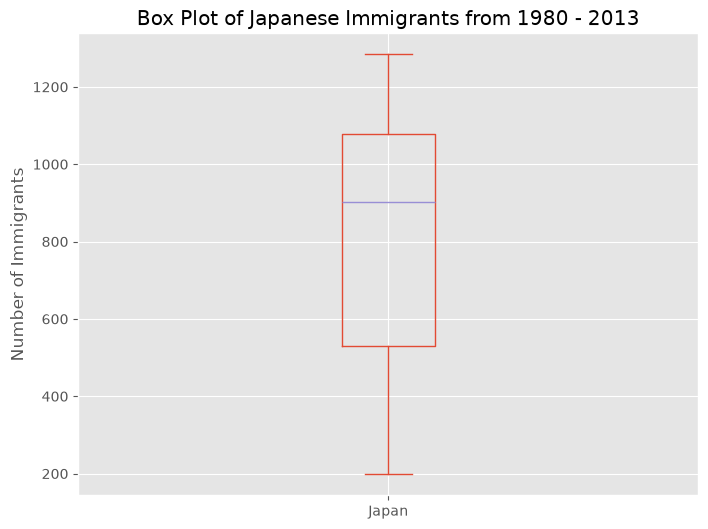

Country,Japan
count,34.000000
mean,814.911765
std,337.219771
min,198.000000
25%,529.000000
50%,902.000000
75%,1079.000000
max,1284.000000


In [14]:
df_japan = df_can.loc[['Japan'], years].transpose()
df_japan.plot(kind='box', figsize=(8, 6))
plt.title('Box Plot of Japanese Immigrants from 1980 - 2013')
plt.ylabel('Number of Immigrants')
plt.show()
df_japan.describe()


**Question.** Compare the distribution of immigration from China and India.

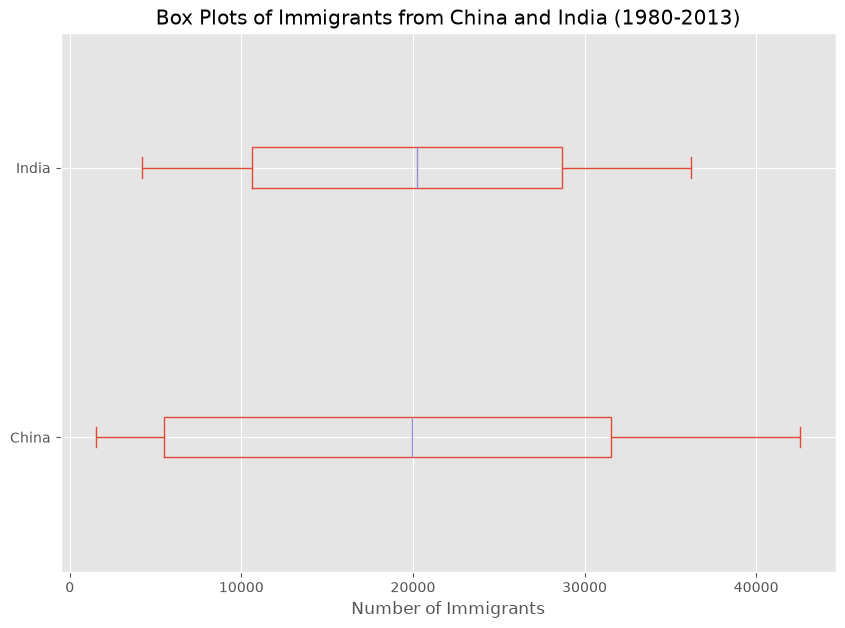

Country,China,India
count,34.000000,34.000000
mean,19410.647059,20350.117647
std,13568.230790,10007.342579
min,1527.000000,4211.000000
25%,5512.750000,10637.750000
50%,19945.000000,20235.000000
75%,31568.500000,28699.500000
max,42584.000000,36210.000000


In [15]:
df_CI = df_can.loc[['China', 'India'], years].transpose()
df_CI.plot(kind='box', figsize=(10, 7), vert=False)
plt.title('Box Plots of Immigrants from China and India (1980-2013)')
plt.xlabel('Number of Immigrants')
plt.show()
df_CI.describe()


**Question.** Box plots of the top 15 countries, grouped by the decades 1980s, 1990s, and 2000s.

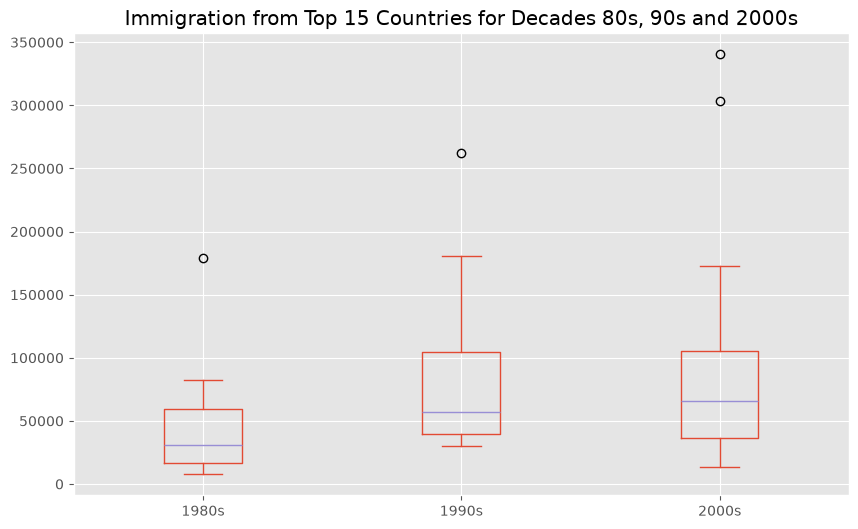

,1980s,1990s,2000s
count,15.000000,15.000000,15.000000
mean,44418.333333,85594.666667,97471.533333
std,44190.676455,68237.560246,100583.204205
min,7613.000000,30028.000000,13629.000000
25%,16698.000000,39259.000000,36101.500000
50%,30638.000000,56915.000000,65794.000000
75%,59183.000000,104451.500000,105505.500000
max,179171.000000,261966.000000,340385.000000


In [16]:
df_top15 = df_can.sort_values(by='Total', ascending=False).head(15)
years_80s = list(map(str, range(1980, 1990)))
years_90s = list(map(str, range(1990, 2000)))
years_00s = list(map(str, range(2000, 2010)))
df_80s = df_top15.loc[:, years_80s].sum(axis=1)
df_90s = df_top15.loc[:, years_90s].sum(axis=1)
df_00s = df_top15.loc[:, years_00s].sum(axis=1)
new_df = pd.DataFrame({'1980s': df_80s, '1990s': df_90s, '2000s': df_00s})
new_df.plot(kind='box', figsize=(10, 6))
plt.title('Immigration from Top 15 Countries for Decades 80s, 90s and 2000s')
plt.show()
new_df.describe()


## Scatter plot

Total immigration to Canada against year, with a least-squares line.

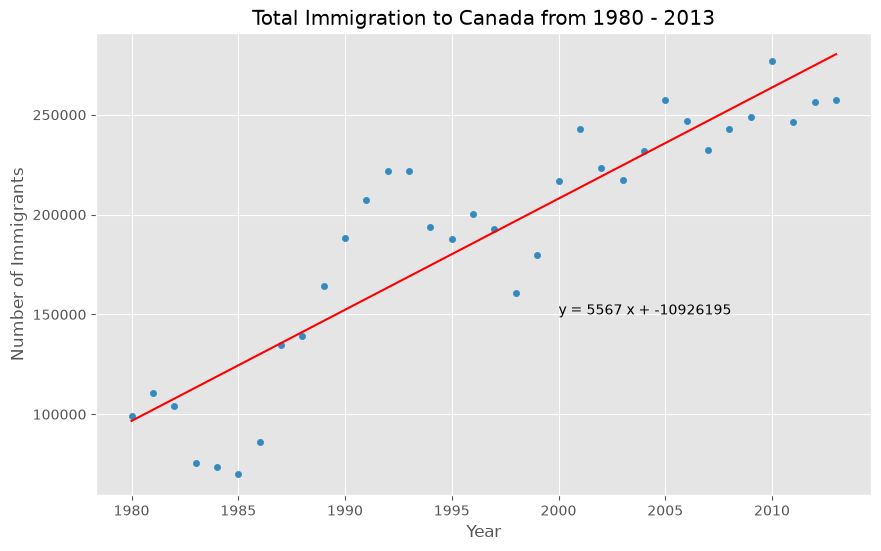

In [17]:
df_tot = pd.DataFrame(df_can[years].sum(axis=0))
df_tot.index = df_tot.index.map(int)
df_tot.reset_index(inplace=True)
df_tot.columns = ['year', 'total']
x = df_tot['year']
y = df_tot['total']
fit = np.polyfit(x, y, deg=1)
df_tot.plot(kind='scatter', x='year', y='total', figsize=(10, 6))
plt.title('Total Immigration to Canada from 1980 - 2013')
plt.xlabel('Year')
plt.ylabel('Number of Immigrants')
plt.plot(x, fit[0] * x + fit[1], color='red')
plt.annotate(f'y = {fit[0]:.0f} x + {fit[1]:.0f}', xy=(2000, 150000))
plt.show()


**Question.** Scatter plot of total immigration from Denmark, Norway, and Sweden, with a regression line.

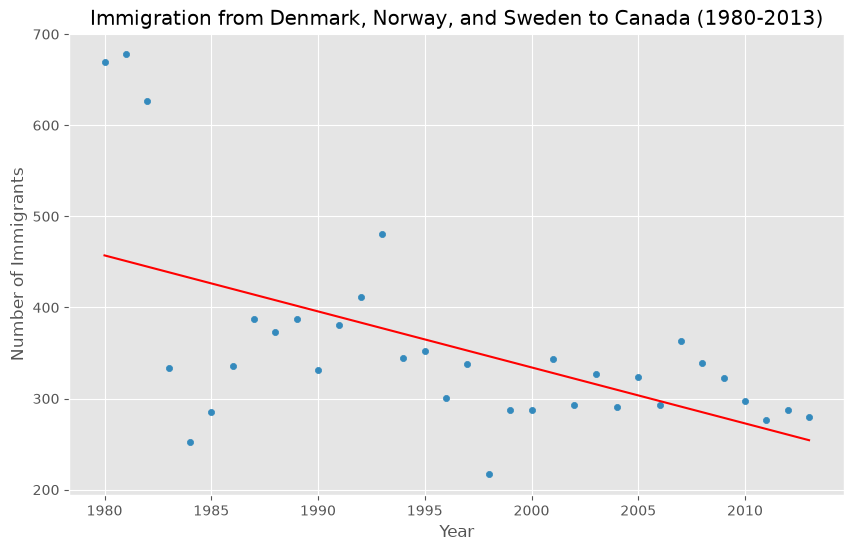

In [18]:
df_countries = df_can.loc[['Denmark', 'Norway', 'Sweden'], years].transpose()
df_total = pd.DataFrame(df_countries.sum(axis=1))
df_total.reset_index(inplace=True)
df_total.columns = ['year', 'total']
df_total['year'] = df_total['year'].astype(int)
fit = np.polyfit(df_total['year'], df_total['total'], deg=1)
df_total.plot(kind='scatter', x='year', y='total', figsize=(10, 6))
plt.title('Immigration from Denmark, Norway, and Sweden to Canada (1980-2013)')
plt.xlabel('Year')
plt.ylabel('Number of Immigrants')
plt.plot(df_total['year'], fit[0] * df_total['year'] + fit[1], color='red')
plt.show()


## Bubble plot

Brazil and Argentina. Bubble area is the immigration count of that year, scaled for display.

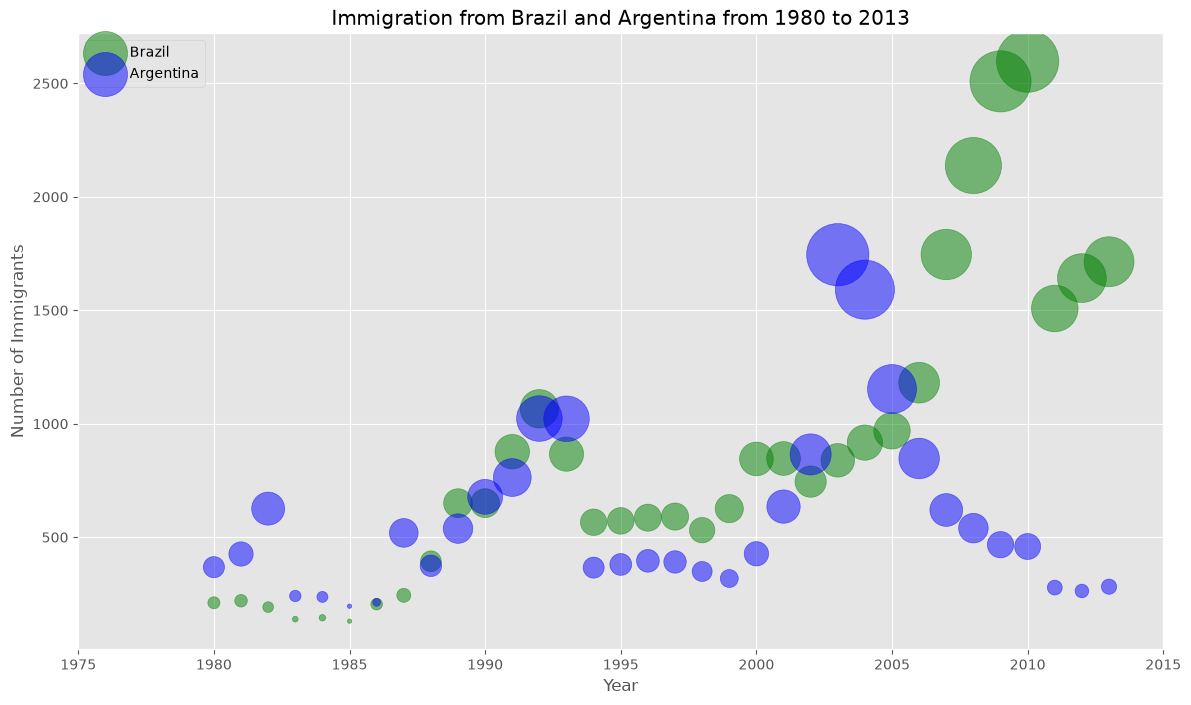

In [19]:

df_can_t = df_can[years].transpose()
df_can_t.index = df_can_t.index.map(int)
df_can_t.index.name = 'Year'
df_can_t.reset_index(inplace=True)

norm_brazil = (df_can_t['Brazil'] - df_can_t['Brazil'].min()) / (df_can_t['Brazil'].max() - df_can_t['Brazil'].min())
norm_argentina = (df_can_t['Argentina'] - df_can_t['Argentina'].min()) / (df_can_t['Argentina'].max() - df_can_t['Argentina'].min())

ax0 = df_can_t.plot(
    kind='scatter', x='Year', y='Brazil', figsize=(14, 8),
    alpha=0.5, color='green', s=norm_brazil * 2000 + 10, xlim=(1975, 2015),
)
ax1 = df_can_t.plot(
    kind='scatter', x='Year', y='Argentina', alpha=0.5, color='blue',
    s=norm_argentina * 2000 + 10, ax=ax0,
)
ax0.set_ylabel('Number of Immigrants')
ax0.set_xlabel('Year')
ax0.set_title('Immigration from Brazil and Argentina from 1980 to 2013')
ax0.legend(['Brazil', 'Argentina'], loc='upper left')
plt.show()


**Question.** Bubble plot comparing China and India.

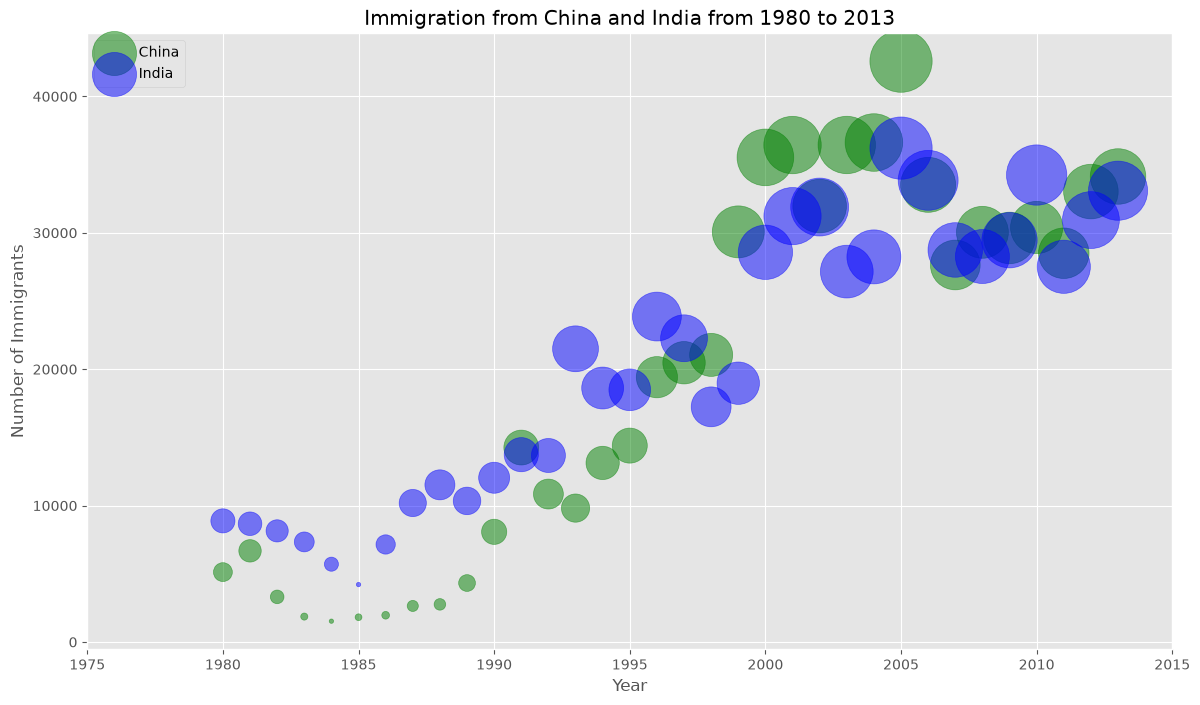

In [20]:

norm_china = (df_can_t['China'] - df_can_t['China'].min()) / (df_can_t['China'].max() - df_can_t['China'].min())
norm_india = (df_can_t['India'] - df_can_t['India'].min()) / (df_can_t['India'].max() - df_can_t['India'].min())
ax0 = df_can_t.plot(
    kind='scatter', x='Year', y='China', figsize=(14, 8),
    alpha=0.5, color='green', s=norm_china * 2000 + 10, xlim=(1975, 2015),
)
ax1 = df_can_t.plot(
    kind='scatter', x='Year', y='India', alpha=0.5, color='blue',
    s=norm_india * 2000 + 10, ax=ax0,
)
ax0.set_ylabel('Number of Immigrants')
ax0.set_xlabel('Year')
ax0.set_title('Immigration from China and India from 1980 to 2013')
ax0.legend(['China', 'India'], loc='upper left')
plt.show()
